# 02. Exploratory Data Analysis (EDA) - Customer Churn

## Executive Summary
Exploratory Data Analysis aims to uncover behavioral patterns, demographic relationships, and contract characteristics that distinguish churners from loyal customers.

### Key Hypotheses to Test:
1. **Contract Type:** Month-to-month contracts exhibit substantially higher churn rates than long-term contracts.
2. **Tenure:** Newer customers have high attrition risk; churn probability drops significantly as tenure increases.
3. **Monthly Charges:** Higher monthly fees correlate with higher churn probability.
4. **Internet Service:** Fiber optic subscribers experience elevated churn due to price or service reliability issues.
5. **Support & Security:** Customers subscribing to Online Security and Tech Support are significantly stickier.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plotting settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", None)

candidates = [
    Path("../data/raw/Customer_Churn.csv"),
    Path("../data/raw/customer_churn.csv"),
    Path("data/raw/Customer_Churn.csv"),
    Path("data/raw/customer_churn.csv"),
]
raw_path = next((p for p in candidates if p.is_file()), None)
df = pd.read_csv(raw_path)

# Convert TotalCharges for EDA exploration
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce").fillna(0.0)
print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset loaded: 7043 rows, 21 columns


## 1. Target Variable: Churn Distribution

C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_19800\2288123140.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="Churn", palette=["#2ecc71", "#e74c3c"])


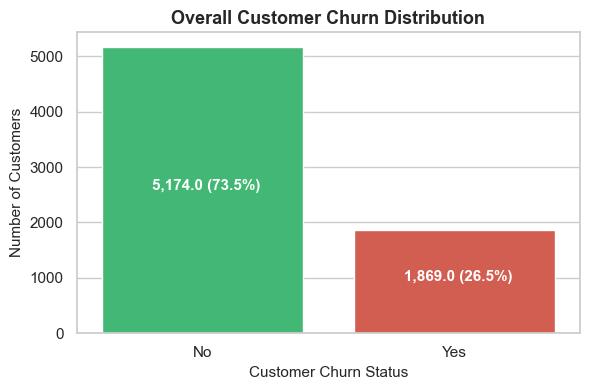

In [2]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Churn", palette=["#2ecc71", "#e74c3c"])
plt.title("Overall Customer Churn Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Customer Churn Status", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)

total = len(df)
for p in ax.patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(f"{p.get_height():,} ({pct})", (p.get_x() + 0.2, p.get_height() / 2),
                color="white", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

## 2. Numerical Features Distribution & Relationship with Churn
We analyze `tenure`, `MonthlyCharges`, and `TotalCharges`.

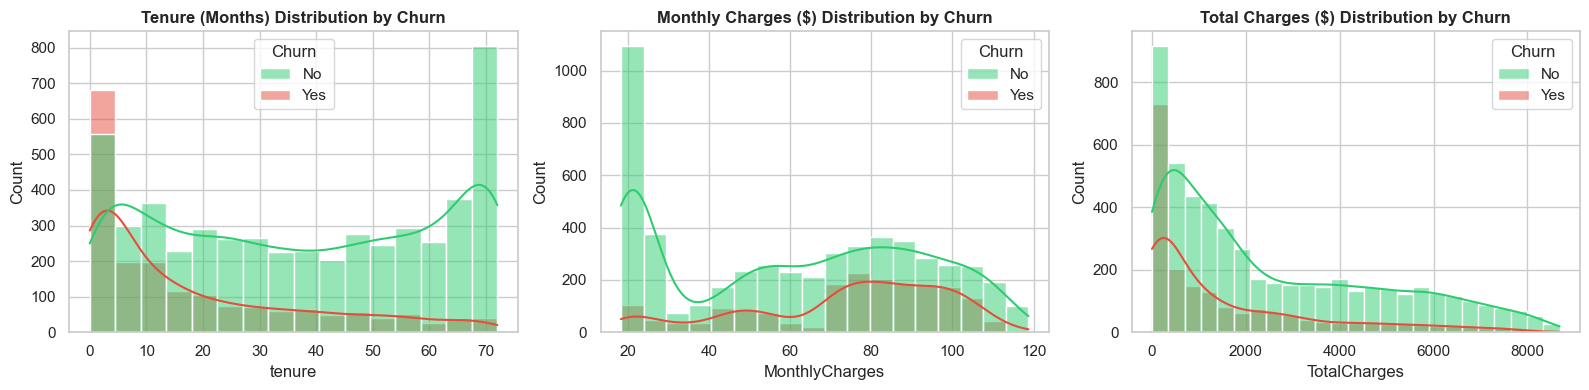

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=df, x="tenure", hue="Churn", kde=True, ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Tenure (Months) Distribution by Churn", fontweight="bold")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, ax=axes[1], palette=["#2ecc71", "#e74c3c"])
axes[1].set_title("Monthly Charges ($) Distribution by Churn", fontweight="bold")

sns.histplot(data=df, x="TotalCharges", hue="Churn", kde=True, ax=axes[2], palette=["#2ecc71", "#e74c3c"])
axes[2].set_title("Total Charges ($) Distribution by Churn", fontweight="bold")

plt.tight_layout()
plt.show()

C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_19800\2178079814.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0], palette=["#2ecc71", "#e74c3c"])
C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_19800\2178079814.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1], palette=["#2ecc71", "#e74c3c"])
C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_19800\2178079814.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="TotalCharg

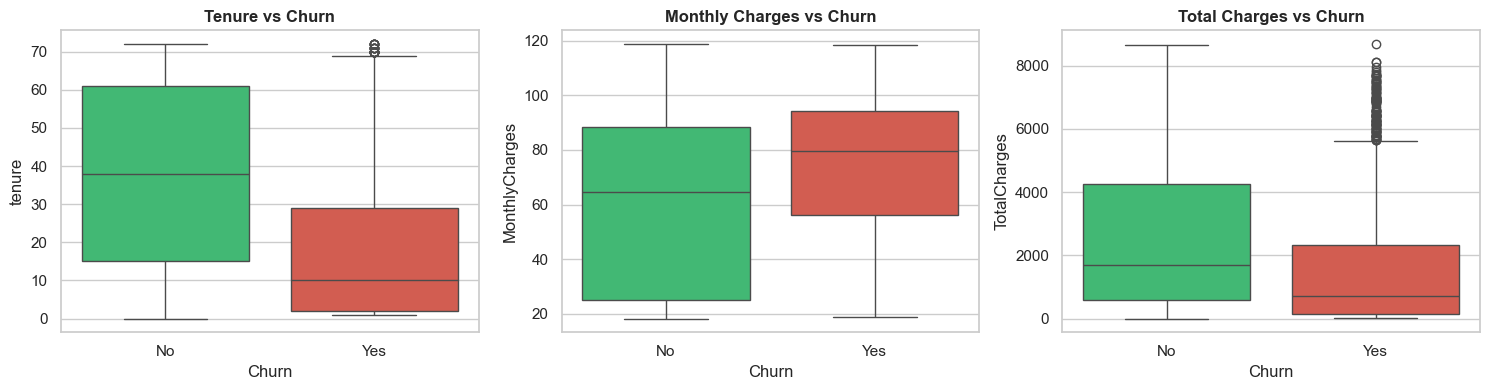

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Tenure vs Churn", fontweight="bold")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1], palette=["#2ecc71", "#e74c3c"])
axes[1].set_title("Monthly Charges vs Churn", fontweight="bold")

sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[2], palette=["#2ecc71", "#e74c3c"])
axes[2].set_title("Total Charges vs Churn", fontweight="bold")

plt.tight_layout()
plt.show()

### Numerical Insights:
- **Tenure:** Churners have a median tenure of ~10 months compared to ~38 months for retained customers. The earliest months represent the highest attrition vulnerability.
- **Monthly Charges:** Churners pay substantially higher median monthly fees (~$80/month) than retained customers (~$65/month). Price sensitivity is evident.
- **Total Charges:** Churners accumulate lower total charges because they leave early.

## 3. Contract Type & Payment Methods (Primary Churn Drivers)

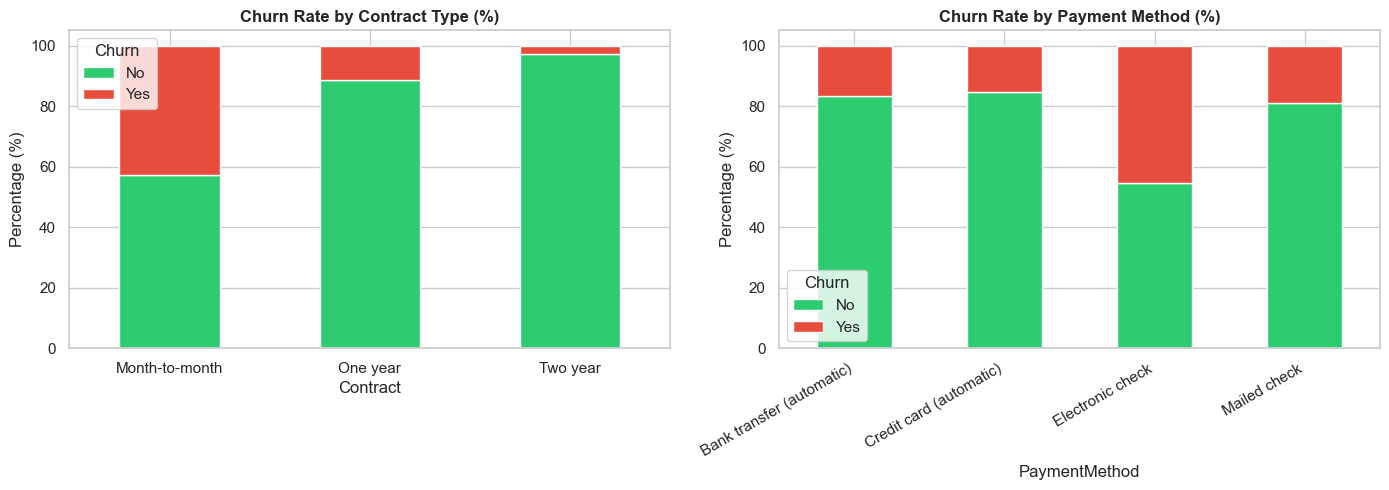

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
contract_churn.plot(kind="bar", stacked=True, color=["#2ecc71", "#e74c3c"], ax=axes[0])
axes[0].set_title("Churn Rate by Contract Type (%)", fontweight="bold")
axes[0].set_ylabel("Percentage (%)")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100
payment_churn.plot(kind="bar", stacked=True, color=["#2ecc71", "#e74c3c"], ax=axes[1])
axes[1].set_title("Churn Rate by Payment Method (%)", fontweight="bold")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [6]:
print("=== Contract Churn Crosstab ===")
print(pd.crosstab(df["Contract"], df["Churn"], margins=True))
print("\n=== Churn Rates by Contract Type (%) ===")
print((pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100).round(2))

=== Contract Churn Crosstab ===
Churn             No   Yes   All
Contract                        
Month-to-month  2220  1655  3875
One year        1307   166  1473
Two year        1647    48  1695
All             5174  1869  7043

=== Churn Rates by Contract Type (%) ===
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


### Contract Observations:
- **Month-to-month:** 42.71% churn rate! This segment accounts for the vast majority of churn.
- **One year:** 11.27% churn rate.
- **Two year:** 2.83% churn rate.
- **Business Implication:** Migrating customers to 1-year or 2-year contracts is the single most potent lever to reduce churn.

## 4. Services & Technology Support Analysis

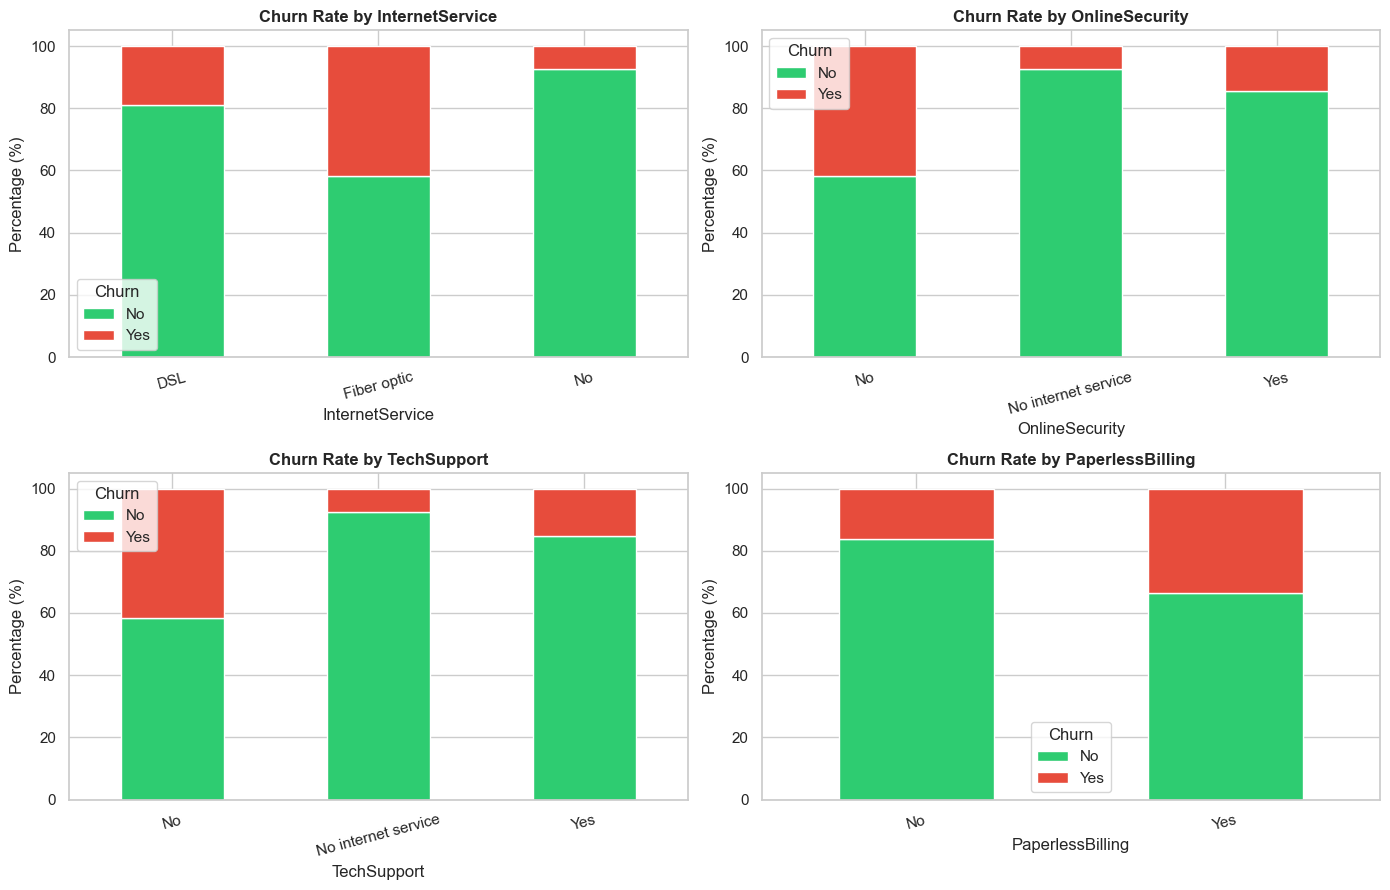

In [7]:
services = ["InternetService", "OnlineSecurity", "TechSupport", "PaperlessBilling"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, service in enumerate(services):
    ct = pd.crosstab(df[service], df["Churn"], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, color=["#2ecc71", "#e74c3c"], ax=axes[i])
    axes[i].set_title(f"Churn Rate by {service}", fontweight="bold")
    axes[i].set_ylabel("Percentage (%)")
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=15)

plt.tight_layout()
plt.show()

## 5. Correlation Analysis of Numerical Features & Churn

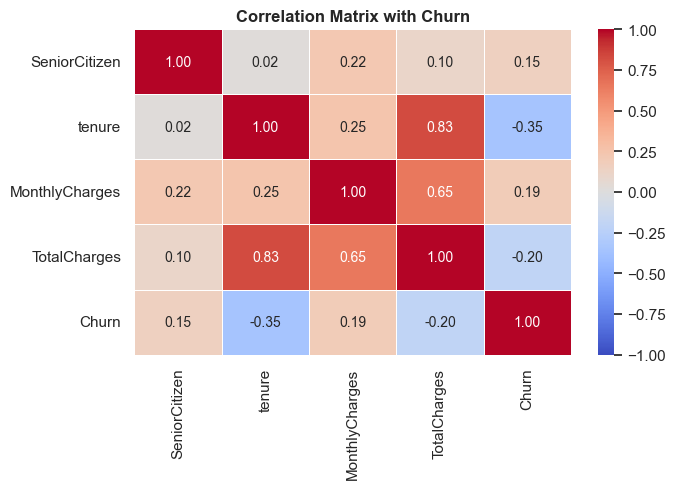

In [8]:
corr_df = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].copy()
corr_df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix with Churn", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Multivariate Cross-Tabulation & Segment Insights

In [9]:
# Pivot table: Mean MonthlyCharges & Mean Tenure by Contract and Churn
pivot_charges = pd.pivot_table(
    df,
    values="MonthlyCharges",
    index="Contract",
    columns="Churn",
    aggfunc=["mean", "count"]
)
print("Monthly Charges Pivot Table:")
display(pivot_charges)

pivot_tenure = pd.pivot_table(
    df,
    values="tenure",
    index="Contract",
    columns="Churn",
    aggfunc="mean"
)
print("\nMean Tenure by Contract & Churn:")
display(pivot_tenure)

Monthly Charges Pivot Table:


mean            count      
Churn                  No        Yes    No   Yes
Contract                                        
Month-to-month  61.462635  73.019396  2220  1655
One year        62.508148  85.050904  1307   166
Two year        60.012477  86.777083  1647    48


Mean Tenure by Contract & Churn:


Churn,No,Yes
Contract,,
Month-to-month,21.033333,14.016918
One year,41.674063,44.963855
Two year,56.602914,61.270833


## Summary of EDA Business Findings
1. **Contract Duration is Decisive:** Month-to-month contracts have a **42.7% churn rate**, compared to **2.8%** for 2-year contracts.
2. **Onboarding Fragility:** Churners exit at a median tenure of **10 months**. The first 90 to 180 days require proactive onboarding.
3. **Fiber Optic & Cost Discontent:** Fiber optic customers churn at **41.9%**, driven by high monthly fees ($80-$100+).
4. **Value-Add Protection Services:** Customers with `OnlineSecurity` and `TechSupport` have less than half the churn rate of customers without them.
5. **Payment Method Effect:** Electronic Check users churn at **45.3%**, whereas Automatic Credit Card/Bank Transfer users churn at under **17%**.